In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path
from scipy.interpolate import make_interp_spline


GRAPH_DIR = Path("graphs")
GRAPH_DIR.mkdir(exist_ok=True)

df = pd.read_csv("results/week3_results.csv")

df

,efSearch,recall_at_10,avg_search_time_ms,min_search_time_ms,max_search_time_ms
0,16,81.0,0.3826,0.1619,2.2119
1,24,87.0,0.2904,0.1493,0.5575
2,32,88.0,0.2371,0.1990,0.2926
3,40,91.0,0.2897,0.2023,0.4392
4,48,93.0,0.2793,0.1816,0.4197
5,56,94.0,0.5885,0.2581,1.7387
6,64,95.0,0.4046,0.2628,0.6347
7,80,97.0,0.5867,0.2907,1.3775
8,96,98.0,0.4751,0.3273,0.6097
9,112,98.0,0.7125,0.3895,1.2478


## Recall vs efSearch

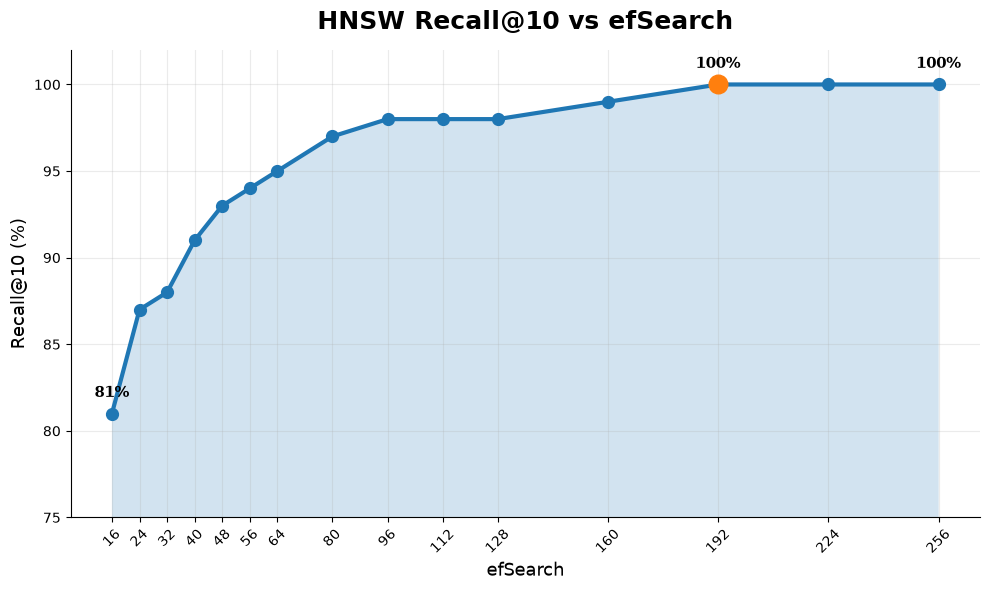

In [21]:

plt.figure(figsize=(10, 6))

x = df["efSearch"]
y = df["recall_at_10"]

# Main line
plt.plot(
    x,
    y,
    linewidth=3,
    marker="o",
    markersize=8,
    markeredgewidth=1.5
)

# Fill area below the curve
plt.fill_between(
    x,
    y,
    75,
    alpha=0.20
)

# Highlight the maximum recall
best_idx = y.idxmax()

plt.scatter(
    x[best_idx],
    y[best_idx],
    s=180,
    zorder=5
)

# Labels on important points
for i in [0, best_idx, len(df) - 1]:
    plt.annotate(
        f"{y[i]:.0f}%",
        (x[i], y[i]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Title
plt.title(
    "HNSW Recall@10 vs efSearch",
    fontsize=18,
    fontweight="bold",
    pad=15
)

# Axis labels
plt.xlabel(
    "efSearch",
    fontsize=13
)

plt.ylabel(
    "Recall@10 (%)",
    fontsize=13
)

# X-axis
plt.xticks(
    x,
    rotation=45
)

# Y-axis
plt.ylim(75, 102)

# Grid
plt.grid(
    True,
    linestyle="-",
    alpha=0.25
)

# Remove top/right borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "efsearch_vs_recall_modern.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Search time vs efSearch

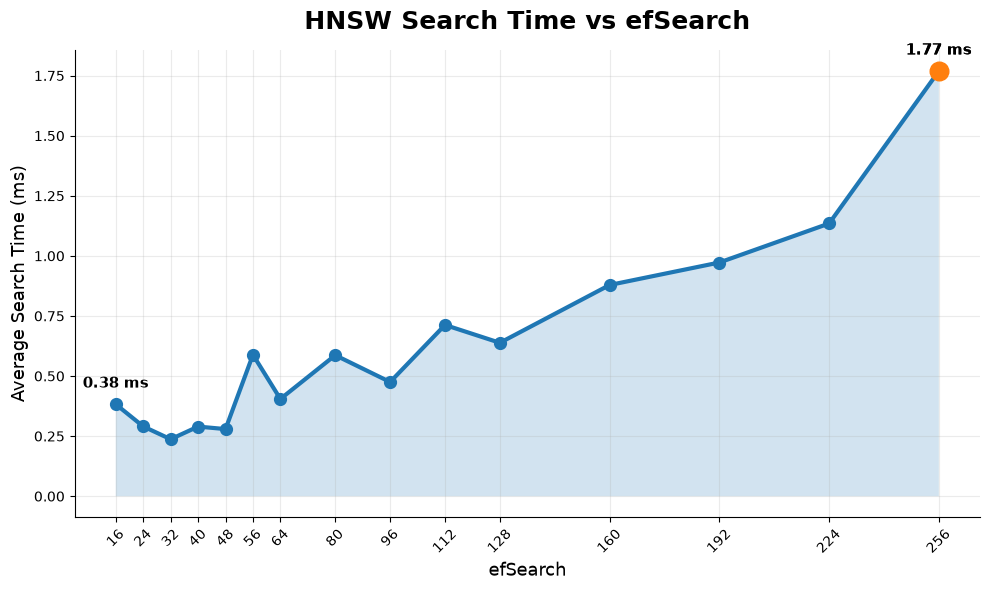

In [11]:
plt.figure(figsize=(10, 6))

x = df["efSearch"]
y = df["avg_search_time_ms"]

# Main line
plt.plot(
    x,
    y,
    linewidth=3,
    marker="o",
    markersize=8,
    markeredgewidth=1.5
)

# Fill area below the curve
plt.fill_between(
    x,
    y,
    0,
    alpha=0.20
)

# Highlight maximum search time
max_idx = y.idxmax()

plt.scatter(
    x[max_idx],
    y[max_idx],
    s=180,
    zorder=5
)

# Labels for important points
for i in [0, max_idx, len(df) - 1]:
    plt.annotate(
        f"{y[i]:.2f} ms",
        (x[i], y[i]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Title
plt.title(
    "HNSW Search Time vs efSearch",
    fontsize=18,
    fontweight="bold",
    pad=15
)

# Axis labels
plt.xlabel(
    "efSearch",
    fontsize=13
)

plt.ylabel(
    "Average Search Time (ms)",
    fontsize=13
)

# X-axis
plt.xticks(
    x,
    rotation=45
)

# Grid
plt.grid(
    True,
    linestyle="-",
    alpha=0.25
)

# Remove unnecessary borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "efsearch_vs_search_time_modern.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Recall vs search time

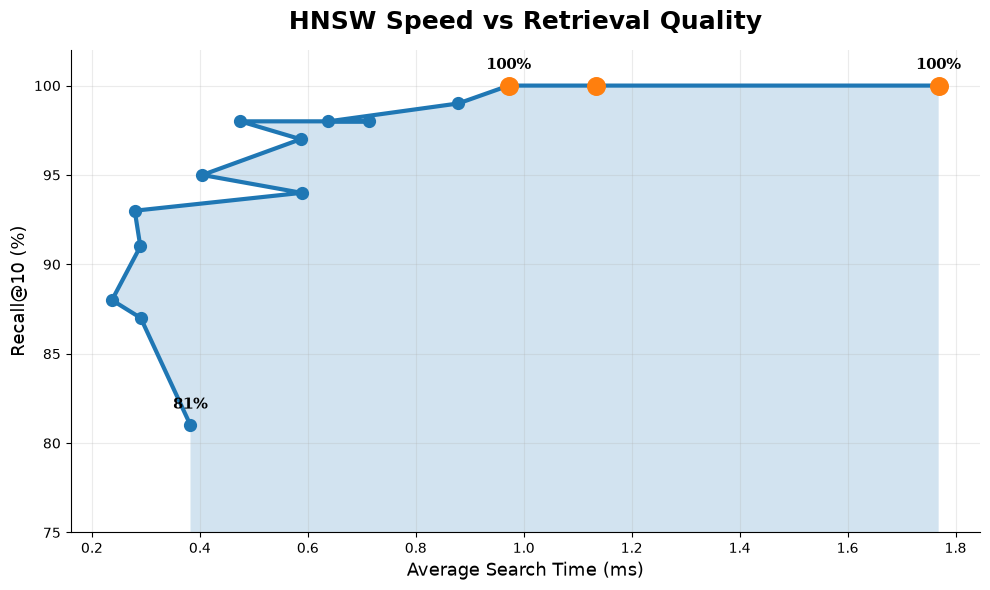

In [12]:
plt.figure(figsize=(10, 6))

x = df["avg_search_time_ms"]
y = df["recall_at_10"]

# Main line
plt.plot(
    x,
    y,
    linewidth=3,
    marker="o",
    markersize=8,
    markeredgewidth=1.5
)

# Fill area below the curve
plt.fill_between(
    x,
    y,
    75,
    alpha=0.20
)

# Highlight 100% recall points
perfect = df["recall_at_10"] == 100

plt.scatter(
    x[perfect],
    y[perfect],
    s=160,
    zorder=5
)

# Label important points
important_points = [
    0,
    df["recall_at_10"].idxmax(),
    len(df) - 1
]

for i in important_points:
    plt.annotate(
        f"{y[i]:.0f}%",
        (x[i], y[i]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Title
plt.title(
    "HNSW Speed vs Retrieval Quality",
    fontsize=18,
    fontweight="bold",
    pad=15
)

# Axis labels
plt.xlabel(
    "Average Search Time (ms)",
    fontsize=13
)

plt.ylabel(
    "Recall@10 (%)",
    fontsize=13
)

# Y-axis
plt.ylim(75, 102)

# Grid
plt.grid(
    True,
    linestyle="-",
    alpha=0.25
)

# Remove unnecessary borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "recall_vs_search_time_modern.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Display the results


In [16]:
print("╔" + "═" * 58 + "╗")
print("║" + "WEEK 3 — HNSW PARAMETER ANALYSIS".center(58) + "║")
print("╚" + "═" * 58 + "╝")

print()

print(f"Dataset Size       : {len(df)} parameter configurations")
print(f"Best Recall@10     : {df['recall_at_10'].max():.0f}%")
print(f"Best efSearch      : {df.loc[df['recall_at_10'].idxmax(), 'efSearch']}")
print(f"Maximum Search Time: {df['avg_search_time_ms'].max():.2f} ms")



╔══════════════════════════════════════════════════════════╗
║             WEEK 3 — HNSW PARAMETER ANALYSIS             ║
╚══════════════════════════════════════════════════════════╝

Dataset Size       : 15 parameter configurations
Best Recall@10     : 100%
Best efSearch      : 192
Maximum Search Time: 1.77 ms
